In [ ]:
import json
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    print("Запуск у Google Colab — переконайтесь, що папка 'src/' завантажена у робочу директорію.")

import src
import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


In [ ]:
from src.config import (
    FIGURES_DIR,
    HISTORIES_DIR,
    LAB8_MODELS_DIR,
    LAB8_SUMMARY_CSV,
    MODEL_SPECS,
    MODELS_DIR,
    RESULTS_DIR,
)
from src.trainer import predict_external_images
from src.visualization import (
    plot_external_predictions_grid,
    plot_lab8_vs_lab9_comparison,
)
import matplotlib.pyplot as plt

ordered_keys = ["vgg16", "resnet50", "inception_v3", "mobilenet_v2"]
lab9_summaries = []
ext_preds_lab9 = {}
ext_preds_lab8 = {}

for key in ordered_keys:
    s_data = json.loads((HISTORIES_DIR / f"{key}_final_summary.json").read_text(encoding="utf-8"))
    m9_path = MODELS_DIR / s_data["save_filename"]
    df_ext9 = predict_external_images(m9_path)
    ext_preds_lab9[s_data["display_name"]] = df_ext9
    s_data["external_accuracy"] = round(float(df_ext9["correct"].mean()), 4)
    s_data["external_mean_conf"] = round(float(df_ext9["confidence"].mean()), 5)
    s_data["external_bce_loss"] = round(float(df_ext9["bce_loss"].mean()), 5)
    lab9_summaries.append(s_data)

    m8_path = LAB8_MODELS_DIR / MODEL_SPECS[key].lab8_save_filename
    if m8_path.exists():
        ext_preds_lab8[s_data["display_name"]] = predict_external_images(m8_path)

lab9_rows = []
for s in lab9_summaries:
    tm = s["test_metrics"]
    lab9_rows.append({
        "Model": s["display_name"],
        "Input Size": f"{s['image_size'][0]}x{s['image_size'][1]}",
        "Unfrozen Scope": f"{s['unfreeze_blocks']} blk ({s['cut_layer_name']}+)",
        "Optimizer & LR": f"{s['optimizer'].upper()} ({s['learning_rate']:.0e})",
        "Total Params": s["total_params"],
        "Trainable Params": s["trainable_params"],
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
        "F1-Score": round(tm["f1"], 4),
        "Test Errors (/2502)": tm["errors_count"],
        "External 10-Photo Acc (%)": round(s["external_accuracy"] * 100, 1),
        "External Mean Conf (%)": round(s["external_mean_conf"] * 100, 2),
        "Size (MB)": s["model_size_mb"],
        "Total Time (s)": round(s["total_pipeline_seconds"], 1),
    })

df_lab9 = pd.DataFrame(lab9_rows)
display(df_lab9)
df_lab9.to_csv(RESULTS_DIR / "lab9_summary_for_lab10.csv", index=False)
(RESULTS_DIR / "lab9_summary_for_lab10.json").write_text(
    json.dumps(lab9_rows, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(f"Експортовано підсумкову таблицю для Лабораторної №10: {RESULTS_DIR / 'lab9_summary_for_lab10.csv'}")

Експортовано підсумкову таблицю для Лабораторної №10: /Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab8/lab9/results/lab9_summary_for_lab10.csv


,Model,Input Size,Unfrozen Scope,Optimizer & LR,Total Params,Trainable Params,Test Accuracy (%),Test Loss,ROC-AUC,F1-Score,Test Errors (/2502),External 10-Photo Acc (%),External Mean Conf (%),Size (MB),Total Time (s)
0,VGG16,224x224,1 blk (block4_pool+),ADAM (5e-06),14854273,7219009,99.08,0.0310,0.99916,0.9908,23,100.0,99.83,56.76,703.7
1,ResNet50,224x224,1 blk (conv4_block6_out+),ADAM (1e-06),24112513,15478273,99.20,0.0230,0.99936,0.9920,20,100.0,99.26,92.62,1022.1
2,InceptionV3,299x299,2 blk (mixed8+),ADAM (1e-05),22327585,11633153,99.32,0.0207,0.99906,0.9932,17,100.0,99.89,86.23,779.2
3,MobileNetV2,224x224,2 blk (block_14_add+),RMSPROP (1e-05),2586177,1523073,99.12,0.0251,0.99918,0.9912,22,90.0,97.69,10.43,647.9


,Model,Lab 8 Trainable Params,Lab 9 Trainable Params,Lab 8 Acc (%),Lab 9 FT Acc (%),Δ Acc (в.п.),Lab 8 Loss,Lab 9 FT Loss,Loss Drop (%),Lab 8 ROC-AUC,Lab 9 FT ROC-AUC,Lab 8 Errors,Lab 9 Errors
0,VGG16,131585,7219009,98.84,99.08,0.24,0.0352,0.0310,11.9,0.99892,0.99916,29,23
1,ResNet50,524801,15478273,99.20,99.20,0.00,0.0230,0.0230,0.0,0.99936,0.99936,20,20
2,InceptionV3,524801,11633153,99.32,99.32,0.00,0.0207,0.0207,0.0,0.99906,0.99906,17,17
3,MobileNetV2,328193,1523073,98.84,99.12,0.28,0.0302,0.0251,16.9,0.99889,0.99918,29,22


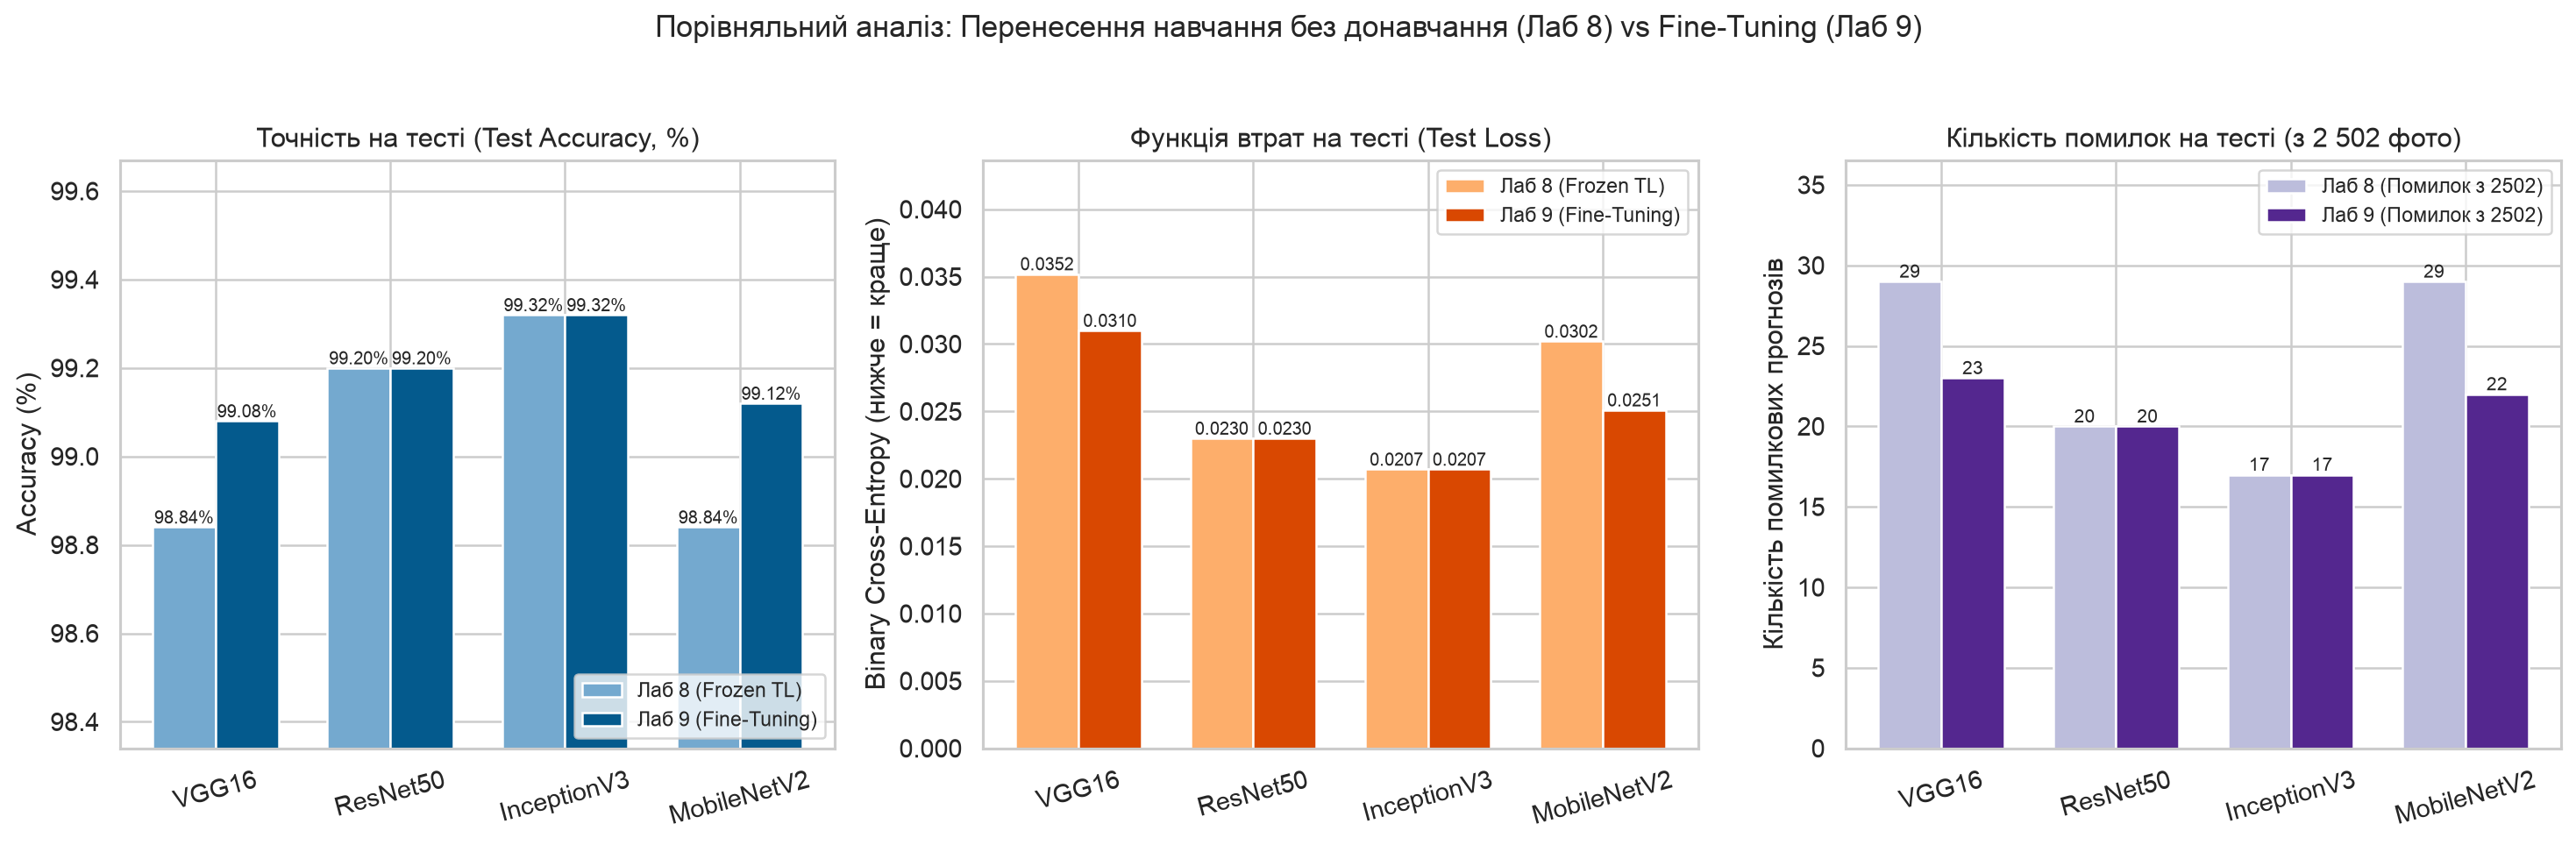

In [3]:
df_lab8_raw = pd.read_csv(LAB8_SUMMARY_CSV)
lab8_by_name = {row["Model"]: row for _, row in df_lab8_raw.iterrows()}

delta_rows = []
for s in lab9_summaries:
    name = s["display_name"]
    tm9 = s["test_metrics"]
    r8 = lab8_by_name[name]
    acc8 = float(r8["Test Accuracy (%)"])
    acc9 = round(tm9["accuracy"] * 100, 2)
    loss8 = float(r8["Test Loss"])
    loss9 = round(tm9["loss"], 4)
    auc8 = float(r8["ROC-AUC"])
    auc9 = round(tm9["roc_auc"], 5)
    err8 = int(round((1.0 - acc8 / 100.0) * tm9["total_samples"]))
    err9 = int(tm9["errors_count"])
    loss_rel_drop = round((loss8 - loss9) / max(loss8, 1e-7) * 100.0, 1)

    delta_rows.append({
        "Model": name,
        "Lab 8 Trainable Params": int(r8["Trainable Params"]),
        "Lab 9 Trainable Params": s["trainable_params"],
        "Lab 8 Acc (%)": acc8,
        "Lab 9 FT Acc (%)": acc9,
        "Δ Acc (в.п.)": round(acc9 - acc8, 2),
        "Lab 8 Loss": loss8,
        "Lab 9 FT Loss": loss9,
        "Loss Drop (%)": loss_rel_drop,
        "Lab 8 ROC-AUC": auc8,
        "Lab 9 FT ROC-AUC": auc9,
        "Lab 8 Errors": err8,
        "Lab 9 Errors": err9,
    })

df_delta = pd.DataFrame(delta_rows)
display(df_delta)
df_delta.to_csv(RESULTS_DIR / "lab8_vs_lab9_comparison.csv", index=False)

plot_lab8_vs_lab9_comparison(df_delta, save_name="05_lab8_vs_lab9_comparison.png")


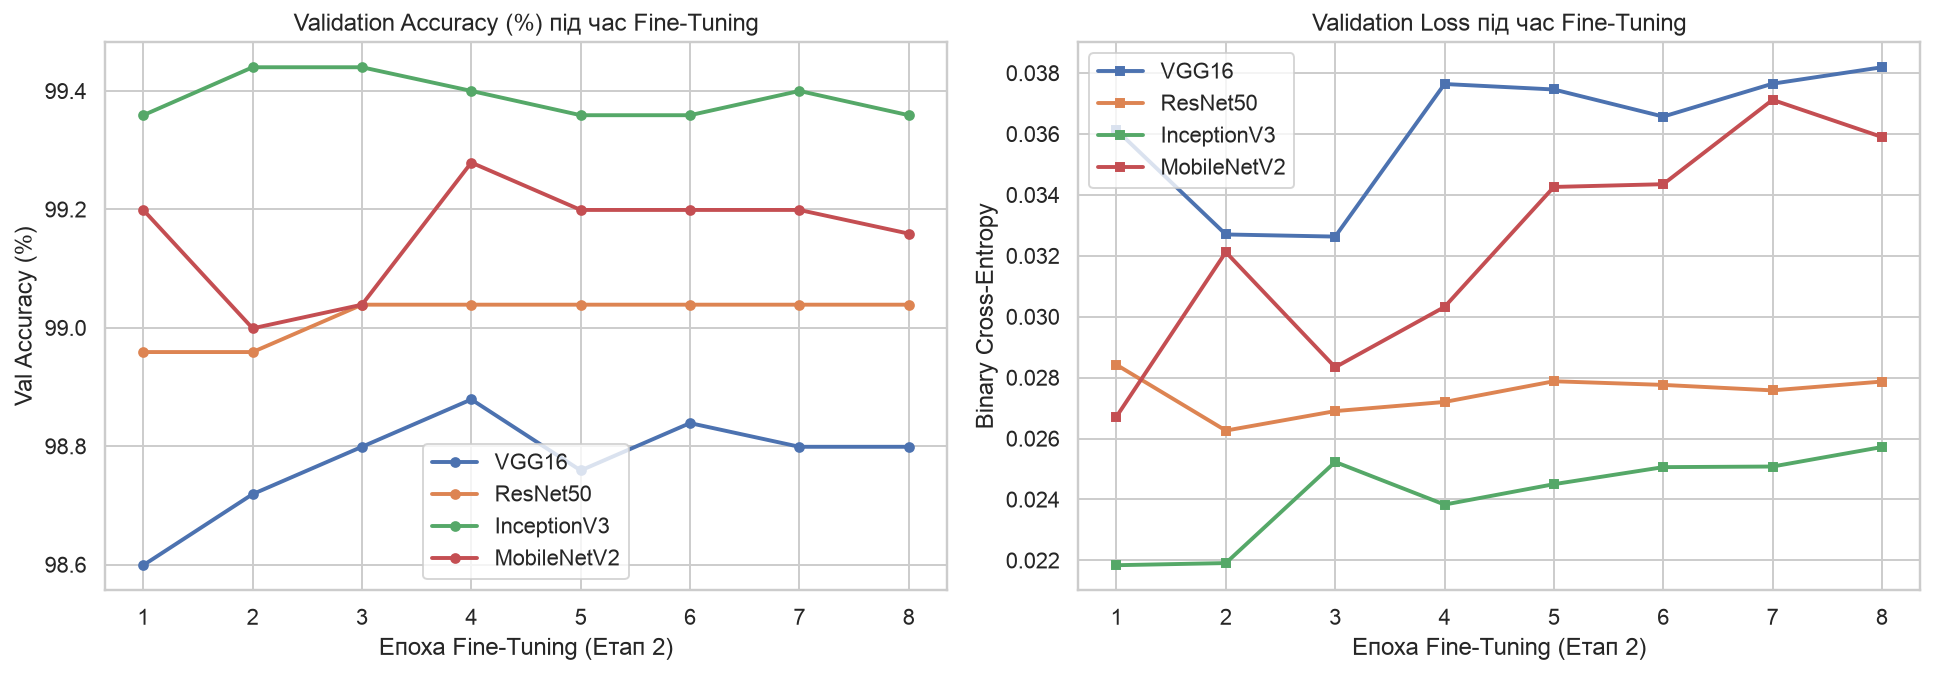

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for s in lab9_summaries:
    ep = np.arange(1, len(s["history"]["val_accuracy"]) + 1)
    ax1.plot(ep, np.asarray(s["history"]["val_accuracy"]) * 100, "o-", linewidth=2, markersize=4.5, label=s["display_name"])
    ax2.plot(ep, s["history"]["val_loss"], "s-", linewidth=2, markersize=4.5, label=s["display_name"])

ax1.set_title("Validation Accuracy (%) під час Fine-Tuning")
ax1.set_xlabel("Епоха Fine-Tuning (Етап 2)")
ax1.set_ylabel("Val Accuracy (%)")
ax1.legend()

ax2.set_title("Validation Loss під час Fine-Tuning")
ax2.set_xlabel("Епоха Fine-Tuning (Етап 2)")
ax2.set_ylabel("Binary Cross-Entropy")
ax2.legend()

plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_ft_architectures_val_curves.png", dpi=180, bbox_inches="tight")
plt.show()


,Model,Lab 8 Ext Acc (%),Lab 9 Ext Acc (%),Lab 8 Mean Confidence (%),Lab 9 Mean Confidence (%),Lab 8 Ext BCE Loss,Lab 9 Ext BCE Loss
0,VGG16,100.0,100.0,99.267,99.826,0.00746,0.00176
1,ResNet50,100.0,100.0,99.260,99.260,0.00768,0.00768
2,InceptionV3,100.0,100.0,99.888,99.888,0.00112,0.00112
3,MobileNetV2,100.0,90.0,95.296,97.694,0.06296,0.14847


,filename,true_class,VGG16 (FT),ResNet50 (FT),InceptionV3 (FT),MobileNetV2 (FT)
0,ext_cat_01_tabby.jpg,cats,✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%)
1,ext_cat_02_orange.jpg,cats,✓ cat (99.93%),✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%)
2,ext_cat_03_white_cat.jpg,cats,✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%)
3,ext_cat_04_kitten.jpg,cats,✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%)
4,ext_cat_05_portrait.jpg,cats,✓ cat (100.00%),✓ cat (100.00%),✓ cat (100.00%),✓ cat (99.99%)
5,ext_dog_01_golden_retriever.jpg,dogs,✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%)
6,ext_dog_02_samoyed.jpg,dogs,✓ dog (98.48%),✓ dog (92.74%),✓ dog (99.07%),✗ cat (77.27%)
7,ext_dog_03_beagle.jpg,dogs,✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%)
8,ext_dog_04_german_shepherd.jpg,dogs,✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%),✓ dog (100.00%)
9,ext_dog_05_pug.jpg,dogs,✓ dog (99.85%),✓ dog (99.86%),✓ dog (99.83%),✓ dog (99.68%)


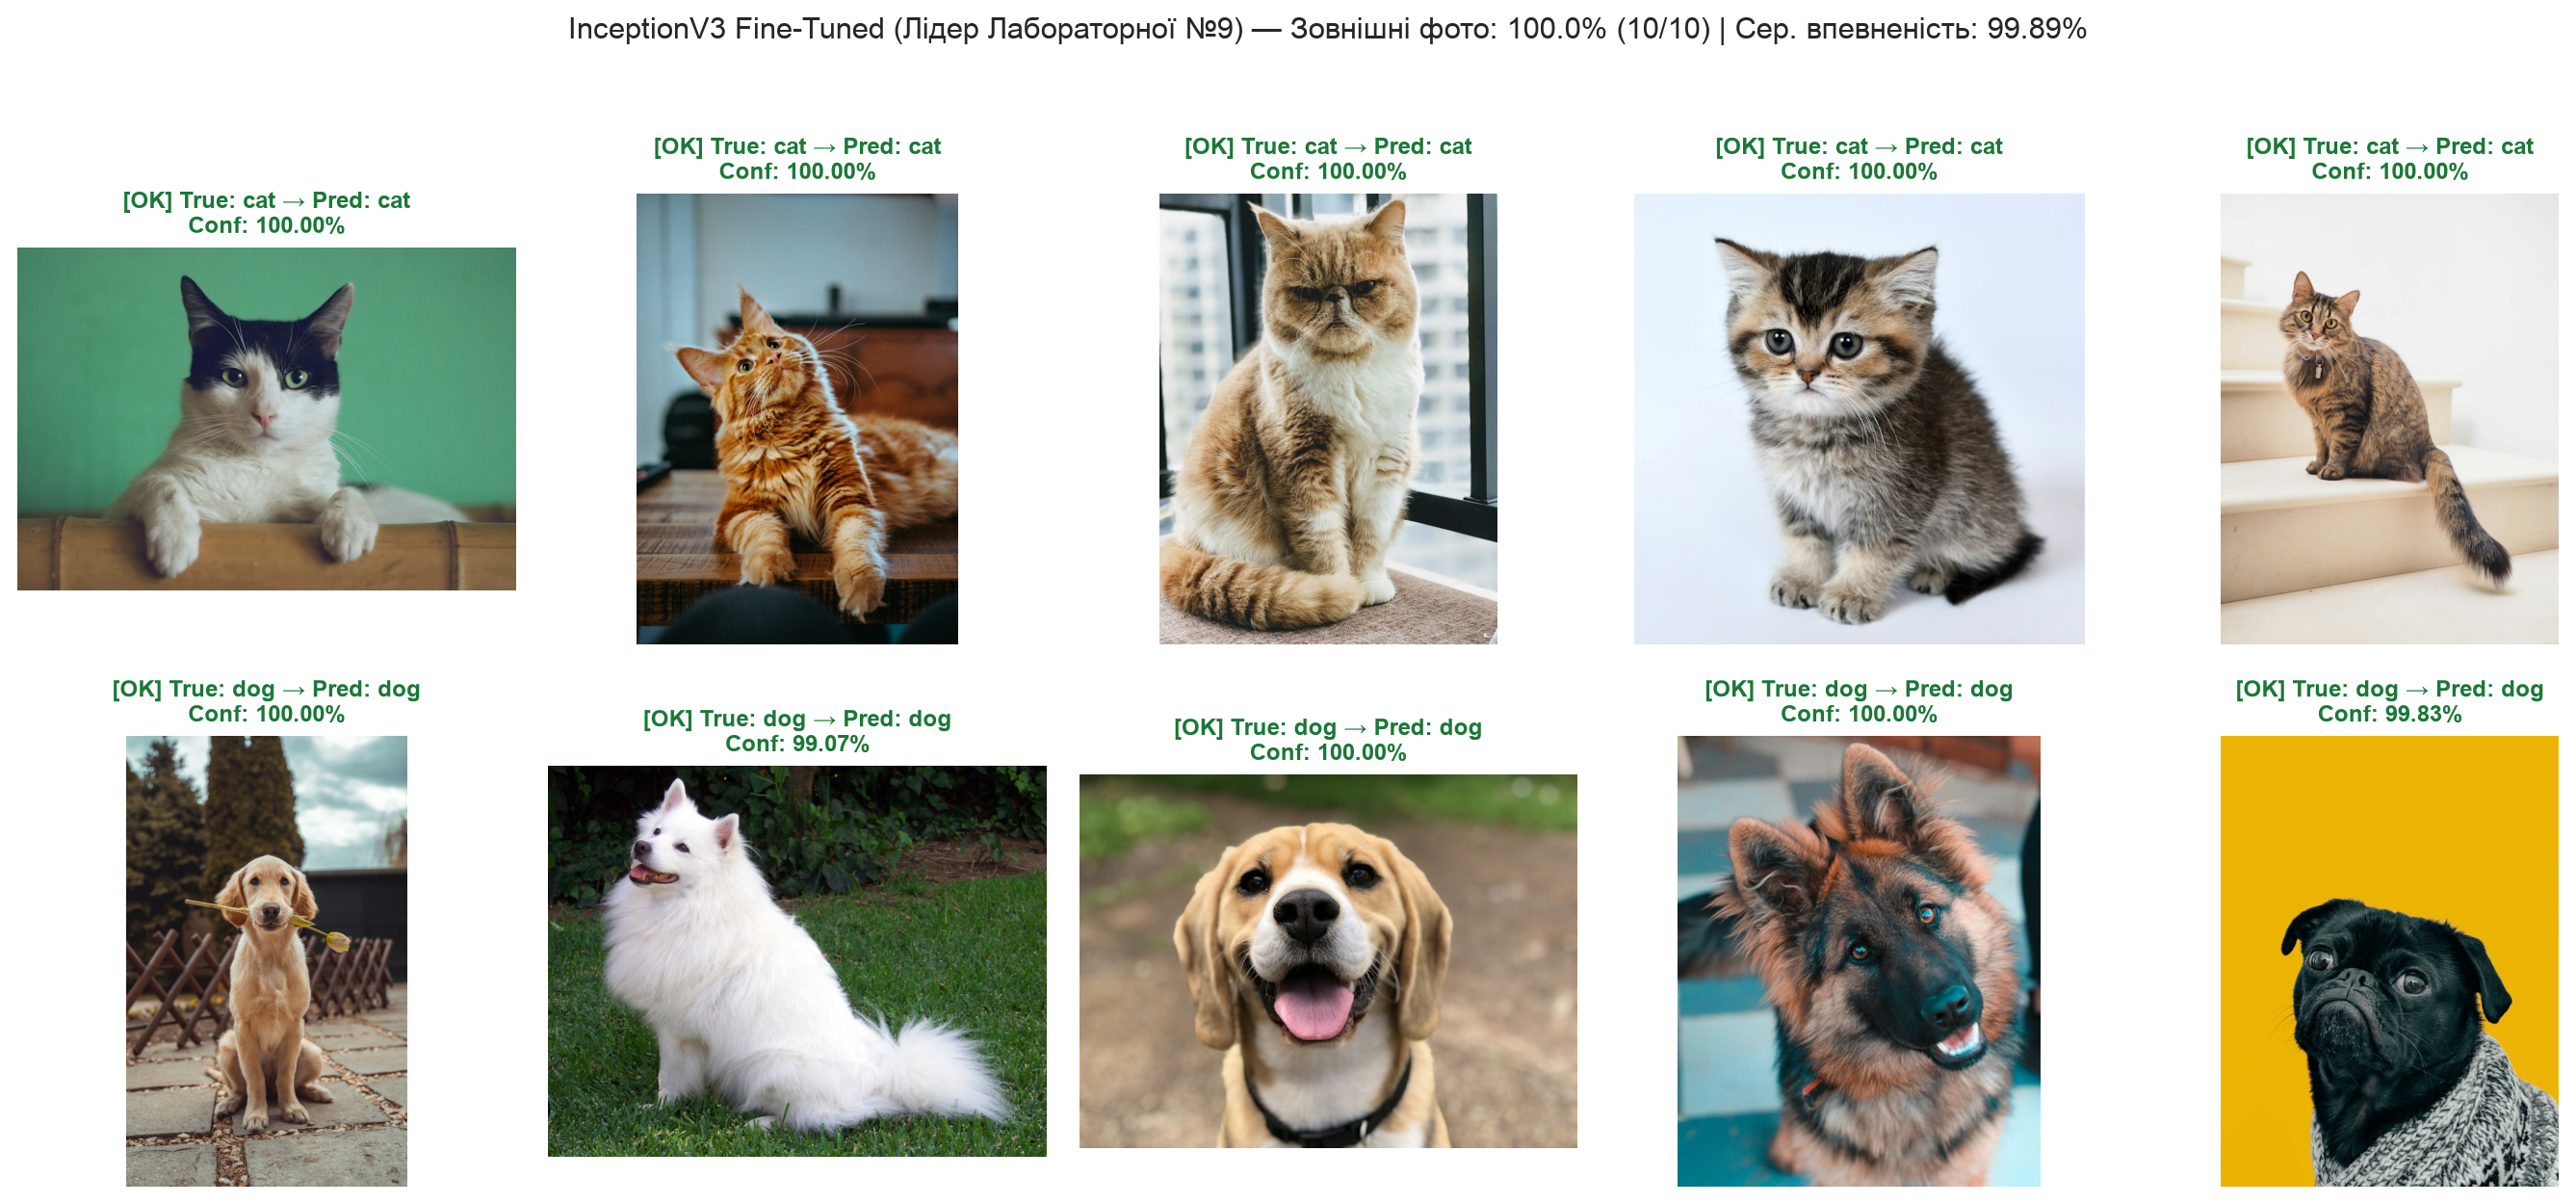

In [ ]:
ext_comp_rows = []
for name in [s["display_name"] for s in lab9_summaries]:
    df9 = ext_preds_lab9[name]
    df8 = ext_preds_lab8.get(name)
    ext_comp_rows.append({
        "Model": name,
        "Lab 8 Ext Acc (%)": round(df8["correct"].mean() * 100, 1) if df8 is not None else None,
        "Lab 9 Ext Acc (%)": round(df9["correct"].mean() * 100, 1),
        "Lab 8 Mean Confidence (%)": round(df8["confidence"].mean() * 100, 3) if df8 is not None else None,
        "Lab 9 Mean Confidence (%)": round(df9["confidence"].mean() * 100, 3),
        "Lab 8 Ext BCE Loss": round(df8["bce_loss"].mean(), 5) if df8 is not None else None,
        "Lab 9 Ext BCE Loss": round(df9["bce_loss"].mean(), 5),
    })

df_ext_summary = pd.DataFrame(ext_comp_rows)
display(df_ext_summary)
df_ext_summary.to_csv(RESULTS_DIR / "external_lab8_vs_lab9.csv", index=False)

per_photo_df = next(iter(ext_preds_lab9.values()))[["filename", "true_class"]].copy()
for name, df9 in ext_preds_lab9.items():
    per_photo_df[f"{name} (FT)"] = [
        f"{'✓' if ok else '✗'} {pred[:-1]} ({conf*100:.2f}%)"
        for ok, pred, conf in zip(df9["correct"], df9["pred_class"], df9["confidence"], strict=True)
    ]
display(per_photo_df)

best_overall_name = df_lab9.sort_values(["Test Accuracy (%)", "ROC-AUC"], ascending=[False, False]).iloc[0]["Model"]
plot_external_predictions_grid(
    ext_preds_lab9[best_overall_name],
    model_title=f"{best_overall_name} Fine-Tuned (Лідер Лабораторної №9)",
    save_name="05_best_model_external_grid.png",
)
